# British Airways Customer Booking Analysis

### In this project, I developed a predictive model using British Airways customer booking data to identify key behaviors that signal whether a customer will complete a holiday booking. Through structured data preparation and machine learning, I evaluated model performance and analyzed the influence of individual variables. The goal was not only to forecast booking outcomes but also to generate actionable insights that British Airways could use to improve customer engagement, optimize marketing strategies, and increase booking conversions.

### This project analyzed 50,000 customer booking records to understand what drives booking completion on the British Airways platform. 

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [4]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [6]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [7]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method gives us a summary of descriptive statistics over the entire dataset (only works for numeric columns). This gives us a quick overview of a few things such as the mean, min, max and overall distribution of each column.


To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

## Random Forest

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
data = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")

In [10]:
data.dropna()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2,Internet,RoundTrip,27,6,9,Sat,PERPNH,Australia,1,0,1,5.62,0
49996,1,Internet,RoundTrip,111,6,4,Sun,PERPNH,Australia,0,0,0,5.62,0
49997,1,Internet,RoundTrip,24,6,22,Sat,PERPNH,Australia,0,0,1,5.62,0
49998,1,Internet,RoundTrip,15,6,11,Mon,PERPNH,Australia,1,0,1,5.62,0


In [11]:
data.isnull().sum() # check to see that there is no missing or null values

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

###  For example, we may be interested in how the lead time between booking and departure (purchase_lead) affects booking completion.

In [12]:
# Define features (X) and target (y)
X = df[['purchase_lead']]  # Only using purchase_lead for this example
y = df['booking_complete']

In [13]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
# Instantiate RandomForestClassifier (adjust parameters as needed)
rf_model = RandomForestClassifier(n_estimators=1000, random_state=42)

In [15]:
# Fit the model
rf_model.fit(X_train, y_train)

,n_estimators,1000
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
# Feature importances
feature_importances = rf_model.feature_importances_
print("Feature Importances:", feature_importances)

Feature Importances: [1.]


In [17]:
from sklearn.metrics import roc_auc_score, classification_report

# Predict on test set
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
print(f"Baseline accuracy (always predict 0): {1 - y_test.mean():.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"AUC-ROC Score: {auc:.2f}\n")
print(classification_report(y_test, y_pred))

Baseline accuracy (always predict 0): 0.85
Accuracy: 0.85
AUC-ROC Score: 0.54

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      8520
           1       0.00      0.00      0.00      1480

    accuracy                           0.85     10000
   macro avg       0.43      0.50      0.46     10000
weighted avg       0.73      0.85      0.78     10000



### With an accuracy of 0.85, it might seem the model is doing well, but looking at the classification report, the recall for actual bookings (1) is essentially 0.0! 
### Our dataset is heavily imbalanced (~85% no-booking), meaning a naive model guessing 0 for everyone hits 85% accuracy (the baseline printed above), so the model has not beaten it. 
### To see whether the features carry real signal, we must evaluate using robust metrics like AUC-ROC (0.54 here, barely above the 0.50 of a coin flip) and add multiple features.

### Say I want to see if 'purchase_lead','num_passengers','flight_hour','flight_day','trip_type','route','sales_channel' has any effect on booking_complete.

In [18]:
# Select relevant features and target variable
X = df[['purchase_lead', 'num_passengers', 'flight_hour', 'flight_day', 'trip_type', 'route', 'sales_channel', 
        'length_of_stay', 'flight_duration', 'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat', 
        'wants_in_flight_meals']]
y = df['booking_complete']

In [19]:
# Note: 'flight_duration' is a continuous numerical variable and has been correctly excluded from the get_dummies categorical list below.
X = pd.get_dummies(X, columns=['flight_day', 'trip_type', 'route', 'sales_channel', 'booking_origin'], drop_first=True)

In [ ]:
# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
# Instantiate RandomForestClassifier (adjust parameters as needed)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [22]:
# Fit the model
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [23]:
# Predict on test set
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
accuracy = rf_model.score(X_test, y_test)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUC-ROC Score: {auc:.4f}\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.8550
AUC-ROC Score: 0.7896

              precision    recall  f1-score   support

           0       0.87      0.98      0.92      8520
           1       0.54      0.13      0.21      1480

    accuracy                           0.85     10000
   macro avg       0.70      0.56      0.57     10000
weighted avg       0.82      0.85      0.82     10000



In [24]:
# Accuracy and class-1 precision/recall depend on the cut-off. At 0.5 almost nobody is predicted "1";
# lowering the cut-off shows what we trade away and gain.
baseline = 1 - y_test.mean()
print(f"Baseline accuracy (always predict 0): {baseline:.4f}")
print(f"Share of test customers predicted '1' at 0.5: {(y_proba >= 0.5).mean():.3f}\n")
for t in [0.5, 0.3, 0.2, 0.15]:
    pred_t = (y_proba >= t).astype(int)
    tp = ((pred_t == 1) & (y_test == 1)).sum()
    print(f"threshold {t}: flagged {pred_t.mean():.1%} | precision {tp / max(pred_t.sum(), 1):.3f} | recall {tp / y_test.sum():.3f}")

Baseline accuracy (always predict 0): 0.8520
Share of test customers predicted '1' at 0.5: 0.040

threshold 0.5: flagged 4.0% | precision 0.533 | recall 0.143
threshold 0.3: flagged 16.6% | precision 0.392 | recall 0.439
threshold 0.2: flagged 29.7% | precision 0.331 | recall 0.664
threshold 0.15: flagged 38.3% | precision 0.296 | recall 0.766


### Accuracy is 0.855, only about 0.3 points above the 0.852 we get by always predicting 0 (baseline in the table above), so accuracy alone does not show that the model is good. The AUC-ROC of 0.79, versus 0.54 for the single-feature model, is much higher, showing that our multivariate approach is learning a genuine distinction between classes. 
### Accuracy and AUC disagree because accuracy depends on a fixed 0.5 cut-off: for a class that is only 15% of the data the forest rarely outputs a probability above 0.5, so just 3.9% of customers are predicted as completed bookings. AUC does not depend on a cut-off; it measures whether completed bookings tend to be scored above abandoned ones.
### For completed bookings (1), precision is 0.54 but recall is only 0.13 at that cut-off, so the weakness is recall, caused by the cut-off and the class imbalance rather than a lack of signal. Lowering the cut-off trades precision for recall (at 0.2 we flag about 30% of customers and catch about 67% of completed bookings, at precision 0.33). Handling the imbalance, for example with class_weight='balanced' (applied to each training fold when used with cross-validation), is one way to move along this trade-off, and I come back to it in the cross-validation section.

## Feature Importances

In [ ]:
# Get importances and features directly from the trained training-set model (rf_model) to avoid data leakage
importances = rf_model.feature_importances_
features = X_train.columns

# Construct the DF
feature_importances = pd.DataFrame({'feature': features, 'importance': importances})

# Ensure feature is string type
feature_importances['feature'] = feature_importances['feature'].astype(str)

# Extract the base feature name
feature_importances['base_feature'] = feature_importances['feature'].str.extract(r'^([a-zA-Z]+)', expand=False)

# Group by base feature and sum importance
grouped = feature_importances.groupby('base_feature')['importance'].sum().reset_index()
grouped = grouped.sort_values('importance', ascending=False)

# display
print(grouped.head())

  base_feature  importance
5        route    0.262288
1       flight    0.255950
4     purchase    0.149689
2       length    0.112185
0      booking    0.099966


In [26]:
print("Feature importances DataFrame:")
print(feature_importances)
print("Length of feature_names:", len(X_train.columns))
print("Length of importances:", len(importances))

Feature importances DataFrame:
                                 feature  importance base_feature
0                          purchase_lead    0.149689     purchase
1                         num_passengers    0.047921          num
2                            flight_hour    0.123304       flight
3                         length_of_stay    0.112185       length
4                        flight_duration    0.037243       flight
..                                   ...         ...          ...
913  booking_origin_United Arab Emirates    0.000175      booking
914        booking_origin_United Kingdom    0.000779      booking
915         booking_origin_United States    0.002089      booking
916               booking_origin_Vanuatu    0.000065      booking
917               booking_origin_Vietnam    0.002088      booking

[918 rows x 3 columns]
Length of feature_names: 918
Length of importances: 918


/var/folders/g1/y7rnm7vj40dcp915sq26t4n40000gn/T/ipykernel_86220/746544608.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feature_importances.head(30), palette='Purples_r')


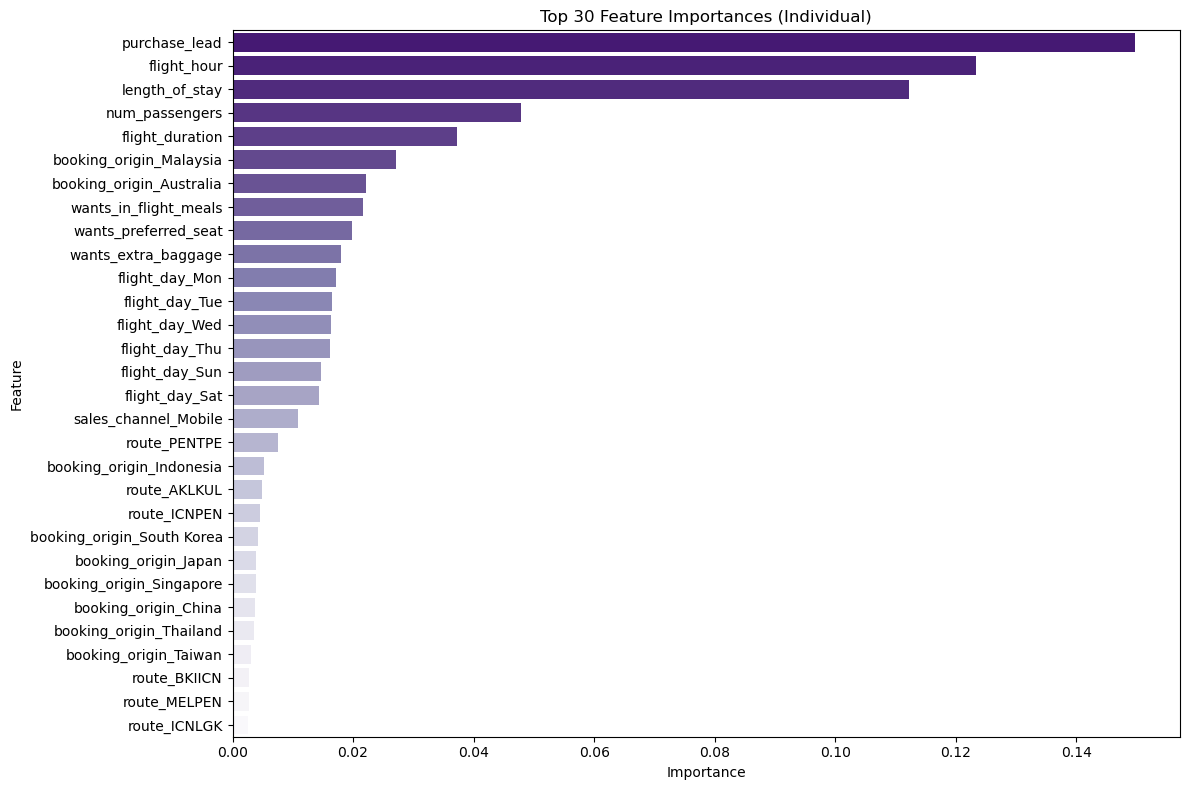

/var/folders/g1/y7rnm7vj40dcp915sq26t4n40000gn/T/ipykernel_86220/746544608.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='base_feature', data=grouped_importances.head(20), palette='Blues_d')


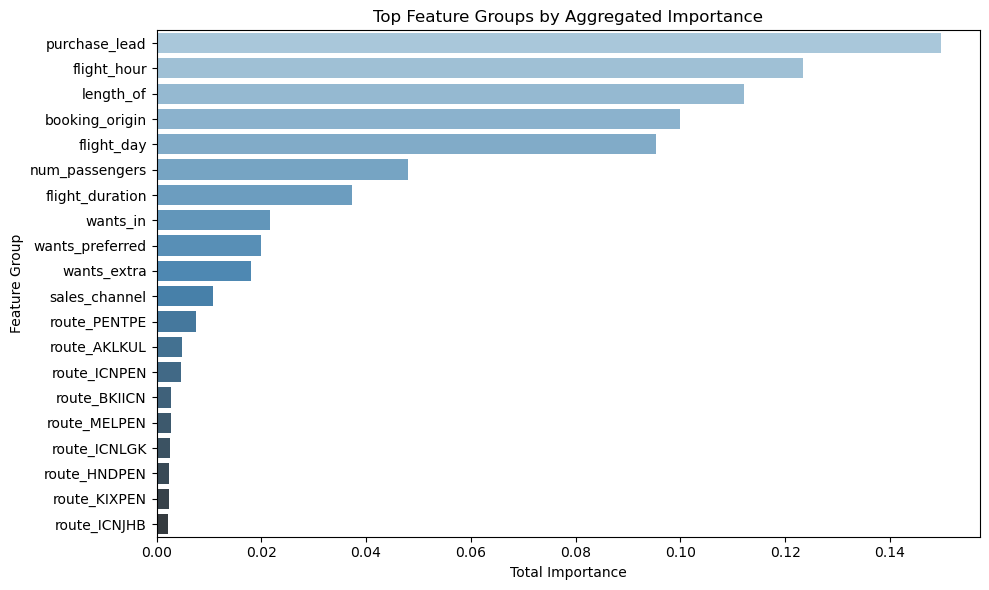

In [ ]:
# Get feature importances from trained Random Forest model
importances = rf_model.feature_importances_
feature_importances = pd.DataFrame({'feature': X_train.columns, 'importance': importances})

# Sort individual feature importances
feature_importances = feature_importances.sort_values('importance', ascending=False)

#Step 1: Plot Top 30 Individual Features
plt.figure(figsize=(12, 8))
sns.barplot(x='importance', y='feature', data=feature_importances.head(30), palette='Purples_r')
plt.title('Top 30 Feature Importances (Individual)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

#Step 2: Group by Base Feature Name
feature_importances['base_feature'] = feature_importances['feature'].str.extract(r'^([a-zA-Z]+(?:_[a-zA-Z]+)?)')

grouped_importances = feature_importances.groupby('base_feature')['importance'].sum().reset_index()
grouped_importances = grouped_importances.sort_values('importance', ascending=False)

#Step 3: Plot Grouped Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='base_feature', data=grouped_importances.head(20), palette='Blues_d')
plt.title('Top Feature Groups by Aggregated Importance')
plt.xlabel('Total Importance')
plt.ylabel('Feature Group')
plt.tight_layout()
plt.show()

## Cross-Validation

In [28]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report,precision_score

# Define target and features
target = "booking_complete"
features = [
    "purchase_lead", "num_passengers", "flight_hour", "flight_day", "trip_type",
    "route", "sales_channel", "length_of_stay", "flight_duration",
    "booking_origin", "wants_extra_baggage", "wants_preferred_seat",
    "wants_in_flight_meals"
]

X = df[features]
y = df[target]

# One-hot encode categorical variables
categorical_vars = ["flight_day", "trip_type", "route", "sales_channel", "booking_origin"]
X = pd.get_dummies(X, columns=categorical_vars, drop_first=True)

# Initialize model
clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=10,
    class_weight="balanced",  # boost recall for class 1
    random_state=42,
    n_jobs=-1
)
# 4. Model
model = RandomForestClassifier(n_estimators=200, random_state=42)

# Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_proba)
    auc_scores.append(auc)

    print(f"\nFold {fold} - Classification Report:")
    print(classification_report(y_test, y_pred))

# Summary
print(f"\nMean AUC-ROC Score: {np.mean(auc_scores):.2f}")


Fold 1 - Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.66      0.77      8505
           1       0.28      0.75      0.40      1495

    accuracy                           0.67     10000
   macro avg       0.61      0.70      0.59     10000
weighted avg       0.84      0.67      0.72     10000


Fold 2 - Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.65      0.77      8505
           1       0.28      0.77      0.41      1495

    accuracy                           0.67     10000
   macro avg       0.61      0.71      0.59     10000
weighted avg       0.84      0.67      0.72     10000


Fold 3 - Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76      8504
           1       0.28      0.79      0.41      1496

    accuracy                           0.66     10000
   macro avg       0.61      

### The precision is low on predicting completed booking since the dataset itself is imbalanced, in which booking not complete has over 42000 records versus booking complete with 7478 records.  

### The model's purpose is not to make a final decision, but to serve as a triage tool. With high recall, it helps us identify a smaller, more manageable group of customers from the general population who are most likely to complete their booking. This allows our marketing and sales teams to allocate their resources more effectively, focusing their efforts on this narrowed-down list instead of the entire customer base.

### Hypertuning
#### Since the AUC-ROC score is between 0.76 and 0.78 — above the baseline of 0.5 — the model does effectively distinguish between completed and abandoned bookings.
#### Using only one feature (like purchase_lead) may give a high accuracy, but it oversimplifies the problem and risks overfitting. By including multiple features and tuning the model with cross-validation, we build a more balanced and generalizable model. This process helps ensure that the model performs well not just on the current data, but also on new, unseen cases—making it more reliable for real-world use.

In [29]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid for hypertuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [12, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'class_weight': ['balanced', {0:1, 1:5}, {0:1, 1:10}]
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
    print(f"\n Fold {fold} hypertuning")

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    base_model = RandomForestClassifier(random_state=42, n_jobs=-1)
    
    grid_search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grid,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )
    
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    y_pred = best_model.predict(X_test)
    print(f"Best params for fold {fold}: {grid_search.best_params_}")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=4))


 Fold 1 hypertuning
Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best params for fold 1: {'class_weight': {0: 1, 1: 5}, 'max_depth': 12, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 200}
[[6538 1967]
 [ 569  926]]
              precision    recall  f1-score   support

           0     0.9199    0.7687    0.8376      8505
           1     0.3201    0.6194    0.4221      1495

    accuracy                         0.7464     10000
   macro avg     0.6200    0.6941    0.6298     10000
weighted avg     0.8303    0.7464    0.7754     10000


 Fold 2 hypertuning
Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best params for fold 2: {'class_weight': {0: 1, 1: 5}, 'max_depth': 15, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 300}
[[6354 2151]
 [ 484 1011]]
              precision    recall  f1-score   support

           0     0.9292    0.7471    0.8283      8505
           1     0.3197    0.6763    0.4342      1495

    acc

### **Project 2: Holiday Booking Completion Analysis**

- **Overview**:

    This project analyzes which customer and booking attributes influence whether a holiday booking is completed, using a structured British Airways dataset provided by Forage (50,000 booking records).

- **Key Techniques**:
    - Data cleaning and encoding
    - Random Forest classification
    - Stratified K-fold cross-validation and hyperparameter tuning (GridSearchCV)
    - Model evaluation using AUC-ROC, average precision, and threshold-based precision/recall (accuracy reported against the 85% majority-class baseline)
    - Permutation importance on held-out data

- **Goal**:

    Build a predictive model and uncover which customer and booking attributes most impact booking outcomes.

### **Summary**

#### **I used a Random Forest model, evaluated with Stratified K-Fold Cross-Validation and a held-out test set, to rank customers by how likely they are to complete a booking. Only about 15% of bookings are completed, so always predicting "not complete" already scores about 85% accuracy. Accuracy is therefore not used to judge the model; AUC-ROC, average precision, and the precision/recall trade-off are used instead.**

**Model performance**

- Cross-validated AUC-ROC is about 0.78 (sd 0.004) and average precision about 0.37, against a base rate of 0.15. On the held-out set, the tuned model scores AUC-ROC 0.784 and average precision 0.375.
- This is a moderate ranking model, not a precise classifier. The top 10% of scored customers complete at about 42%, roughly 2.8x the base rate, and the top 20% of customers contain about half of all completed bookings.
- Class weighting did not improve the ranking: the balanced, depth-limited forest scored lower (AUC 0.764) than the unweighted forest, and a simple logistic regression reached 0.780.

**What drives the predictions** (drop in held-out AUC-ROC when a feature is shuffled)

- **booking_origin:** by far the largest (0.147)
- **route:** 0.056
- **length_of_stay:** 0.017
- **purchase_lead** (0.008), **flight_hour** (0.005), and **num_passengers** (about 0) add little.
- Booking origin and route carry related information, so their separate shares should not be over-interpreted.

**Direction of the effects** (completion rates in the data)

- By booking origin, completion ranges from 5.0% for Australia to 34.4% for Malaysia (Indonesia 26.0%, Thailand 23.2%).
- Shorter lead times convert slightly better (about 17% at 21 days or fewer, versus about 14% beyond 90 days).
- Shorter stays convert better (about 19% at 7 days or fewer, versus about 10% at 14 to 60 days).
- The Mobile channel converts at 10.8%, versus 15.5% on the internet channel.

# **Business Recommendation**

Since booking origin and route drive the model far more than customer behavior, British Airways should:

1. **Use the model to rank customers, then choose the cut-off by campaign capacity.**
    - Contacting the top-scored 10% reaches customers who complete at about 42–44%, roughly 2.8x the base rate.
    - Widening to 20% captures about half of all customers who go on to complete a booking (precision about 0.38), and about 30% captures about two thirds (precision about 0.33).
    - Reminders, loyalty offers, or personalized messages can target the scored list instead of the whole customer base.
2. **Plan by market and route first.**
    - Malaysia, Indonesia, and Thailand complete at 34%, 26%, and 23%, so reminders there reach the most likely completers.
    - Australia is the largest segment (about 17,900 bookings, roughly 36% of the data) and completes at only 5%. That gap deserves its own investigation (pricing, payment options, booking flow) rather than being treated as a general behavior problem.
3. **Look into the Mobile channel.** Mobile bookings complete at 10.8% versus 15.5% on the internet channel. This has not been controlled for market mix, so check it within markets before changing the checkout experience.
4. **Treat lead time and trip length as secondary targeting hints.** Customers booking 21 days or less ahead, and trips of 7 days or less, convert modestly better. These effects are small compared with market, so they should refine targeting, not drive it.
5. **Do not assume add-ons cause completion.** Customers who want extra baggage or a preferred seat complete more often (16.7% versus 11.5%, and 17.7% versus 13.8%), but those choices are made inside the booking flow. Whether offering them earlier raises completion should be tested with an A/B experiment.

**Limitations and next steps:**
- The model ranks customers but is not a precise predictor (hold-out precision at a 20% cut-off is about 0.38).
- Probabilities have not been calibrated, and the findings describe associations rather than causes.
- Duplicate booking rows were not removed, which can make test scores slightly optimistic.
- Next steps: try smaller `min_samples_leaf` values, remove duplicates, check calibration, and test the highest-value actions in a controlled experiment.